# RNAseq project - immunotherapy

## Transcriptomic analysis of Anti-PD-1 response in melanoma

End-to-end reanalysis of GEO RNA-seq data using Python (GEOparse, PyDESeq2, GSEApy) including QC, normalization, differential expression and pathway enrichment

In [1]:
# imports
from pathlib import Path 

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from sklearn.decomposition import PCA
# output directories
TABLE_DIR = Path("../results/tables")
FIGURE_DIR = Path("../results/figures")
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


**Exports:** selected final tables are written to `../results/tables/` as CSV files and selected main figures to `../results/figures/` as PDF files.


### 1. metadata

#### 1.1 Load and process the metadata

In [3]:
metadata = pd.read_csv("../data/raw/metadata_raw.csv")
metadata.head()

,sample,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,...,contact_zip/postal_code,contact_country,instrument_model,library_selection,library_source,library_strategy,relation,supplementary_file_1,series_id,data_row_count
0,GSM2069823,Pt1,GSM2069823,Public on Mar 18 2016,Feb 23 2016,Dec 03 2024,SRA,1,tumor biopsy_Progressive Disease,Homo sapiens,...,90095,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE78220,0
1,GSM2069824,Pt2,GSM2069824,Public on Mar 18 2016,Feb 23 2016,Dec 03 2024,SRA,1,tumor biopsy_Partial Response,Homo sapiens,...,90095,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE78220,0
2,GSM2069825,Pt4,GSM2069825,Public on Mar 18 2016,Feb 23 2016,Dec 03 2024,SRA,1,tumor biopsy_Partial Response,Homo sapiens,...,90095,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE78220,0
3,GSM2069826,Pt5,GSM2069826,Public on Mar 18 2016,Feb 23 2016,Dec 03 2024,SRA,1,tumor biopsy_Partial Response,Homo sapiens,...,90095,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE78220,0
4,GSM2069827,Pt6,GSM2069827,Public on Mar 18 2016,Feb 23 2016,Dec 03 2024,SRA,1,tumor biopsy_Partial Response,Homo sapiens,...,90095,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE78220,0


In [4]:
metadata.columns

Index(['sample', 'title', 'geo_accession', 'status', 'submission_date',
       'last_update_date', 'type', 'channel_count', 'source_name_ch1',
       'organism_ch1', 'taxid_ch1', 'characteristics_ch1', 'molecule_ch1',
       'extract_protocol_ch1', 'description', 'data_processing', 'platform_id',
       'contact_name', 'contact_email', 'contact_department',
       'contact_institute', 'contact_address', 'contact_city', 'contact_state',
       'contact_zip/postal_code', 'contact_country', 'instrument_model',
       'library_selection', 'library_source', 'library_strategy', 'relation',
       'supplementary_file_1', 'series_id', 'data_row_count'],
      dtype='str')

In [5]:
metadata.columns.tolist()

['sample',
 'title',
 'geo_accession',
 'status',
 'submission_date',
 'last_update_date',
 'type',
 'channel_count',
 'source_name_ch1',
 'organism_ch1',
 'taxid_ch1',
 'characteristics_ch1',
 'molecule_ch1',
 'extract_protocol_ch1',
 'description',
 'data_processing',
 'platform_id',
 'contact_name',
 'contact_email',
 'contact_department',
 'contact_institute',
 'contact_address',
 'contact_city',
 'contact_state',
 'contact_zip/postal_code',
 'contact_country',
 'instrument_model',
 'library_selection',
 'library_source',
 'library_strategy',
 'relation',
 'supplementary_file_1',
 'series_id',
 'data_row_count']

In [6]:
cat_cols = metadata.select_dtypes(include=["str", "category", "bool"]).columns.tolist()
# num_cols = meta.select_dtypes(include=["number"]).columns.tolist()

In [7]:
for col in cat_cols:
    print(f"\n#### {col}")
    print(metadata[col].value_counts(dropna=False))


#### sample
sample
GSM2069823    1
GSM2069824    1
GSM2069825    1
GSM2069826    1
GSM2069827    1
GSM2069828    1
GSM2069829    1
GSM2069830    1
GSM2069831    1
GSM2069832    1
GSM2069833    1
GSM2069834    1
GSM2069835    1
GSM2069836    1
GSM2069837    1
GSM2069838    1
GSM2069839    1
GSM2069840    1
GSM2069841    1
GSM2069842    1
GSM2069843    1
GSM2069844    1
GSM2069845    1
GSM2069846    1
GSM2069847    1
GSM2069848    1
GSM2069849    1
GSM2069850    1
Name: count, dtype: int64

#### title
title
Pt1      1
Pt2      1
Pt4      1
Pt5      1
Pt6      1
Pt7      1
Pt8      1
Pt9      1
Pt10     1
Pt12     1
Pt13     1
Pt14     1
Pt15     1
Pt16     1
Pt19     1
Pt20     1
Pt22     1
Pt23     1
Pt25     1
Pt27A    1
Pt27B    1
Pt28     1
Pt29     1
Pt31     1
Pt32     1
Pt35     1
Pt37     1
Pt38     1
Name: count, dtype: int64

#### geo_accession
geo_accession
GSM2069823    1
GSM2069824    1
GSM2069825    1
GSM2069826    1
GSM2069827    1
GSM2069828    1
GSM2069829    1
GSM20698

In [8]:
metadata.isna().sum()

sample                     0
title                      0
geo_accession              0
status                     0
submission_date            0
last_update_date           0
type                       0
channel_count              0
source_name_ch1            0
organism_ch1               0
taxid_ch1                  0
characteristics_ch1        0
molecule_ch1               0
extract_protocol_ch1       0
description                0
data_processing            0
platform_id                0
contact_name               0
contact_email              0
contact_department         0
contact_institute          0
contact_address            0
contact_city               0
contact_state              0
contact_zip/postal_code    0
contact_country            0
instrument_model           0
library_selection          0
library_source             0
library_strategy           0
relation                   0
supplementary_file_1       0
series_id                  0
data_row_count             0
dtype: int64

In [9]:
metadata["characteristics_ch1"].iloc[0]

'patient id: Pt1 | anti-pd-1 response: Progressive Disease | study site: UCLA | gender: F | age (yrs): 66 | disease status: M1b | overall survival (days): 607 | vital status: Dead | previous mapki: N | anatomical location: L post. Thigh, inf., SC | nras: Q61L | treatment: Pembrolizumab | biopsy time: pre-treatment | tissue: Melanoma biopsies | stranded/unstranded rnaseq: unstranded'

In [10]:
meta = metadata.copy()

In [11]:
# # extract patient ID
# meta["patient"] = meta["characteristics_ch1"].str.extract(r"patient id:\s*([^|]+)")

# # extract response
# meta["response"] = meta["characteristics_ch1"].str.extract(r"anti-pd-1 response:\s*([^|]+)")

# # extract sex
# meta["sex"] = meta["characteristics_ch1"].str.extract(r"gender:\s*([^|]+)")

# # extract age
# meta["age"] = meta["characteristics_ch1"].str.extract(r"age (yrs):\s*([^|]+)")

# # extract disease status
# meta["disease_status"] = meta["characteristics_ch1"].str.extract(r"disease status:\s*([^|]+)")


In [12]:
# parse the characteristics column
def parse_characteristics(text):
    fields = {}

    for item in text.split(" | "):
        if ": " in item:
            key, value = item.split(": ", 1)
            fields[key.strip()] = value.strip()

    return fields

# Convert each row into a dictionary
parsed = meta["characteristics_ch1"].apply(parse_characteristics)

# Expand dictionaries into columns
parsed_df = pd.DataFrame(parsed.tolist())

# Merge with original metadata
meta = pd.concat([meta, parsed_df], axis=1)

In [13]:
# clean the column names
meta.columns = (
    meta.columns
        .str.lower()
        .str.replace(" ", "_", regex=False)
        .str.replace("-", "_", regex=False)
        .str.replace("(", "", regex=False)
        .str.replace(")", "", regex=False)
        .str.replace("/", "_", regex=False)
)

In [14]:
meta.columns.to_list

<bound method IndexOpsMixin.tolist of Index(['sample', 'title', 'geo_accession', 'status', 'submission_date',
       'last_update_date', 'type', 'channel_count', 'source_name_ch1',
       'organism_ch1', 'taxid_ch1', 'characteristics_ch1', 'molecule_ch1',
       'extract_protocol_ch1', 'description', 'data_processing', 'platform_id',
       'contact_name', 'contact_email', 'contact_department',
       'contact_institute', 'contact_address', 'contact_city', 'contact_state',
       'contact_zip_postal_code', 'contact_country', 'instrument_model',
       'library_selection', 'library_source', 'library_strategy', 'relation',
       'supplementary_file_1', 'series_id', 'data_row_count', 'patient_id',
       'anti_pd_1_response', 'study_site', 'gender', 'age_yrs',
       'disease_status', 'overall_survival_days', 'vital_status',
       'previous_mapki', 'anatomical_location', 'nras', 'treatment',
       'biopsy_time', 'tissue', 'stranded_unstranded_rnaseq', 'nf1', 'braf'],
      dtype='str')

In [15]:
# rename some columns
meta = meta.rename(columns={
    "anti_pd_1_response": "response",
    "age_yrs": "age",
    "overall_survival_days": "survival",
    "title": "patient",
    "gender": "sex"
})

In [16]:
meta[["sample", "patient", "patient_id", "sex", "age", "response", "disease_status", "survival", "biopsy_time"]].head()

,sample,patient,patient_id,sex,age,response,disease_status,survival,biopsy_time
0,GSM2069823,Pt1,Pt1,F,66,Progressive Disease,M1b,607,pre-treatment
1,GSM2069824,Pt2,Pt2,M,55,Partial Response,M1c,927,pre-treatment
2,GSM2069825,Pt4,Pt4,M,62,Partial Response,M1c,948,pre-treatment
3,GSM2069826,Pt5,Pt5,M,61,Partial Response,M1c,439,pre-treatment
4,GSM2069827,Pt6,Pt6,M,51,Partial Response,M1c,882,pre-treatment


In [17]:
# inspect relationships between meta variables
print(pd.crosstab(meta["response"], meta["sex"]))
print(pd.crosstab(meta["response"], meta["previous_mapki"]))
print(pd.crosstab(meta["response"], meta["biopsy_time"]))
print(pd.crosstab(meta["response"], meta["disease_status"]))

sex                  F  M
response                 
Complete Response    1  4
Partial Response     3  7
Progressive Disease  4  9
previous_mapki       N  Y
response                 
Complete Response    5  0
Partial Response     4  6
Progressive Disease  7  6
biopsy_time          on-treatment  pre-treatment
response                                        
Complete Response               0              5
Partial Response                0             10
Progressive Disease             1             12
disease_status       M0  M1a  M1b  M1c
response                              
Complete Response     1    1    0    3
Partial Response      0    0    1    9
Progressive Disease   0    1    2   10


In [18]:
sample_counts = (
    meta.groupby("patient")
        .size()
        .sort_values(ascending=False)
)

sample_counts

patient
Pt1      1
Pt10     1
Pt12     1
Pt13     1
Pt14     1
Pt15     1
Pt16     1
Pt19     1
Pt2      1
Pt20     1
Pt22     1
Pt23     1
Pt25     1
Pt27A    1
Pt27B    1
Pt28     1
Pt29     1
Pt31     1
Pt32     1
Pt35     1
Pt37     1
Pt38     1
Pt4      1
Pt5      1
Pt6      1
Pt7      1
Pt8      1
Pt9      1
dtype: int64

In [19]:
(meta.groupby("patient_id")["sample"]
     .agg(list)
     .loc[lambda s: s.str.len() > 1])

patient_id
Pt27    [GSM2069842, GSM2069843]
Name: sample, dtype: object

In [20]:
# Standardize patient identifiers
meta["patient"] = (
    meta["patient"]
    .replace({
        "Pt27A": "Pt27",
        "Pt27B": "Pt27"
    })
)


# Identify duplicated patients
duplicate_patients = (
    meta.loc[
        meta["patient"].duplicated(keep=False),
        ["sample", "patient", "response", "biopsy_time"]
    ]
    .sort_values("patient")
)

duplicate_patients

,sample,patient,response,biopsy_time
19,GSM2069842,Pt27,Complete Response,pre-treatment
20,GSM2069843,Pt27,Complete Response,pre-treatment


In [21]:
meta["biopsy_time"].unique()
meta["biopsy_time"].value_counts()

biopsy_time
pre-treatment    27
on-treatment      1
Name: count, dtype: int64

In [22]:
# Define analysis cohort
# remove Pt27B
meta = meta[meta["sample"] != "GSM2069843"]
meta = meta[meta["biopsy_time"] == "pre-treatment"]

excluded_samples = pd.DataFrame({
    "sample": ["GSM2069843"],
    "patient": ["Pt27"],
    "reason": ["Duplicate pretreatment biopsy; Pt27A retained"]
})


In [23]:
meta["response"] = meta["response"].replace({
    "Partial Response": "responder",
    "Complete Response": "responder",
    "Progressive Disease": "non-responder"
})

In [24]:
keep_columns = ["sample","patient","response","sex","age","disease_status","vital_status","previous_mapki","biopsy_time"]

meta = meta[keep_columns]

In [25]:
print(meta.shape)
print(meta.columns)
meta.describe()

(26, 9)
Index(['sample', 'patient', 'response', 'sex', 'age', 'disease_status',
       'vital_status', 'previous_mapki', 'biopsy_time'],
      dtype='str')


,sample,patient,response,sex,age,disease_status,vital_status,previous_mapki,biopsy_time
count,26,26,26,26,26,26,26,26,26
unique,26,26,2,2,21,4,2,2,1
top,GSM2069823,Pt1,responder,M,55,M1c,Alive,N,pre-treatment
freq,1,1,14,18,3,21,15,15,26


In [26]:
meta.info()

<class 'pandas.DataFrame'>
Index: 26 entries, 0 to 27
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   sample          26 non-null     str  
 1   patient         26 non-null     str  
 2   response        26 non-null     str  
 3   sex             26 non-null     str  
 4   age             26 non-null     str  
 5   disease_status  26 non-null     str  
 6   vital_status    26 non-null     str  
 7   previous_mapki  26 non-null     str  
 8   biopsy_time     26 non-null     str  
dtypes: str(9)
memory usage: 2.0 KB


In [27]:
# save clean/processed meta
# meta.to_csv("../data/processed/meta.csv")

meta.to_csv(TABLE_DIR / "metadata_analysis_cohort.csv")


## Study design

### Primary question
Do pretreatment bulk RNA-seq profiles from metastatic melanoma distinguish patients who subsequently responded to anti-PD-1 therapy from those with progressive disease, after accounting for prior MAPK-inhibitor exposure?

### Analysis cohort and endpoint
- **Dataset:** GEO GSE78220 (Hugo et al., *Cell*, 2016), melanoma biopsies profiled by bulk RNA-seq before anti-PD-1 therapy.
- **Unit of analysis:** one pretreatment tumor biopsy per patient.
- **Primary response definition:** Complete Response (CR) or Partial Response (PR) = `responder`; Progressive Disease (PD) = `non-responder`.
- **Included samples:** pretreatment biopsies only, after removal of the duplicate Pt27B biopsy.
- **Excluded samples:** Pt27B (`GSM2069843`; duplicate pretreatment biopsy, Pt27A retained) and the Pt16 on-treatment biopsy.
- **Expected final cohort:** 26 samples (14 responders, 12 non-responders).

### Statistical design
- **Primary contrast:** responder vs non-responder.
- **DE model:** `~ response + previous_mapki` using PyDESeq2.
- **Covariate:** previous MAPK-inhibitor exposure, included a priori because prior MAPKi is biologically relevant in this cohort and may affect transcriptional state.
- **Gene filtering:** retain genes with at least 10 raw counts in at least half of the analysis samples.
- **Multiple testing:** Benjamini-Hochberg adjusted P values from DESeq2; portfolio summary uses `padj < 0.05` and `|log2FC| > log2(1.5)` for labelled DE genes.

This is an **associational reanalysis**, not a predictive model-development study: the same cohort is used to estimate response-associated expression differences, and there is no independent test set.

In [28]:
# Study-design summary derived from the cleaned metadata
study_design = pd.DataFrame({
    "item": ["analysis samples", "responders", "non-responders", "previous MAPKi: yes", "previous MAPKi: no"],
    "n": [len(meta), (meta["response"] == "responder").sum(), (meta["response"] == "non-responder").sum(), (meta["previous_mapki"] == "Y").sum(), (meta["previous_mapki"] == "N").sum()]
})
study_design

study_design.to_csv(TABLE_DIR / "study_design_summary.csv", index=False)


#### 2. QC setup

In [29]:
# load raw count data
counts_raw = pd.read_csv("../data/raw/GSE78220_raw_counts_GRCh38.p13_NCBI.tsv", sep="\t")
counts_raw.head()


,GeneID,GSM2069823,GSM2069824,GSM2069825,GSM2069826,GSM2069827,GSM2069828,GSM2069829,GSM2069830,GSM2069831,...,GSM2069841,GSM2069842,GSM2069843,GSM2069844,GSM2069845,GSM2069846,GSM2069847,GSM2069848,GSM2069849,GSM2069850
0,100287102,5,1,8,1,4,5,5,10,8,...,11,4,4,3,1,3,14,3,6,6
1,653635,852,394,1448,1476,1522,1291,655,1651,1541,...,1526,924,989,863,983,783,1028,762,822,1192
2,102466751,22,7,50,13,150,49,27,48,46,...,20,23,55,24,69,17,50,20,15,43
3,107985730,1,0,3,6,5,1,0,5,7,...,2,0,1,1,1,1,4,1,1,0
4,100302278,1,0,1,0,0,0,0,3,1,...,1,0,0,0,1,0,1,0,0,0


In [30]:
print("Raw count matrix:", counts_raw.shape)
print("First columns:", counts_raw.columns[:5].tolist())
print("First GeneIDs:", counts_raw["GeneID"].head(10).tolist())


Raw count matrix: (39376, 29)
First columns: ['GeneID', 'GSM2069823', 'GSM2069824', 'GSM2069825', 'GSM2069826']
First GeneIDs: [100287102, 653635, 102466751, 107985730, 100302278, 645520, 79501, 100996442, 729737, 102725121]


In [31]:
# Make sure GeneID is stored as text
counts_raw["GeneID"] = counts_raw["GeneID"].astype(str)

# Sample IDs from the filtered metadata
sample_ids = meta["sample"].astype(str).tolist()

# Check that every metadata sample is present in the count file
missing_samples = [sample for sample in sample_ids if sample not in counts_raw.columns]

if missing_samples:
    raise ValueError(f"These metadata samples are missing from the count file: {missing_samples}")

# Create the analysis count matrix:
# rows = GeneIDs, columns = the 26 samples from meta, in the same order
counts = (
    counts_raw
    .set_index("GeneID")
    .loc[:, sample_ids]
    .copy()
)

print("Missing samples:", missing_samples)
print("Counts shape:", counts.shape)
print("Index name:", counts.index.name)
print("First GeneIDs:", counts.index[:10].tolist())
print("First samples:", counts.columns[:10].tolist())


Missing samples: []
Counts shape: (39376, 26)
Index name: GeneID
First GeneIDs: ['100287102', '653635', '102466751', '107985730', '100302278', '645520', '79501', '100996442', '729737', '102725121']
First samples: ['GSM2069823', 'GSM2069824', 'GSM2069825', 'GSM2069826', 'GSM2069827', 'GSM2069828', 'GSM2069829', 'GSM2069830', 'GSM2069831', 'GSM2069832']


In [33]:
counts


,GSM2069823,GSM2069824,GSM2069825,GSM2069826,GSM2069827,GSM2069828,GSM2069829,GSM2069830,GSM2069831,GSM2069832,...,GSM2069840,GSM2069841,GSM2069842,GSM2069844,GSM2069845,GSM2069846,GSM2069847,GSM2069848,GSM2069849,GSM2069850
GeneID,,,,,,,,,,,,,,,,,,,,,
100287102,5,1,8,1,4,5,5,10,8,20,...,13,11,4,3,1,3,14,3,6,6
653635,852,394,1448,1476,1522,1291,655,1651,1541,638,...,970,1526,924,863,983,783,1028,762,822,1192
102466751,22,7,50,13,150,49,27,48,46,21,...,38,20,23,24,69,17,50,20,15,43
107985730,1,0,3,6,5,1,0,5,7,2,...,1,2,0,1,1,1,4,1,1,0
100302278,1,0,1,0,0,0,0,3,1,0,...,0,1,0,0,1,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4541,35525,66501,241629,2166,599466,232311,49003,171416,125901,150017,...,381737,246138,152225,115726,111961,91884,163846,136344,102468,73856
4556,3499,4124,8809,221,15513,14444,3268,16395,8754,7883,...,20494,23599,15738,9255,4998,7582,18156,14780,12115,8026
4519,107038,233872,906518,8156,1508670,770608,351087,500930,465938,504001,...,1227058,696854,304408,206480,344785,293874,243586,158522,310551,334389


In [34]:
counts.iloc[:5, :5]


,GSM2069823,GSM2069824,GSM2069825,GSM2069826,GSM2069827
GeneID,,,,,
100287102,5,1,8,1,4
653635,852,394,1448,1476,1522
102466751,22,7,50,13,150
107985730,1,0,3,6,5
100302278,1,0,1,0,0


In [35]:
# Put metadata in the same sample order as the count matrix
meta = (
    meta
    .set_index("sample")
    .loc[sample_ids]
    .copy()
)


In [36]:
meta


,patient,response,sex,age,disease_status,vital_status,previous_mapki,biopsy_time
sample,,,,,,,,
GSM2069823,Pt1,non-responder,F,66,M1b,Dead,N,pre-treatment
GSM2069824,Pt2,responder,M,55,M1c,Alive,N,pre-treatment
GSM2069825,Pt4,responder,M,62,M1c,Alive,Y,pre-treatment
GSM2069826,Pt5,responder,M,61,M1c,Alive,N,pre-treatment
GSM2069827,Pt6,responder,M,51,M1c,Alive,Y,pre-treatment
GSM2069828,Pt7,non-responder,F,55,M1c,Dead,N,pre-treatment
GSM2069829,Pt8,responder,M,69,M1a,Alive,N,pre-treatment
GSM2069830,Pt9,responder,M,68,M0,Alive,N,pre-treatment
GSM2069831,Pt10,non-responder,M,60,M1a,Alive,Y,pre-treatment


## Quality control

QC is calculated on the unfiltered count matrix for the retained analysis cohort.

In [37]:
# Sample-level QC metrics from raw counts in the retained cohort
qc = pd.DataFrame(index=counts.columns)
qc["library_size"] = counts.sum(axis=0)
qc["detected_genes"] = (counts > 0).sum(axis=0)
qc = qc.join(meta[["response", "previous_mapki"]])
qc.sort_values("library_size")

qc.to_csv(TABLE_DIR / "qc_sample_metrics.csv")


### QC results and interpretation
- **Library size:** total raw counts range from ~32.7M to ~100.2M per sample (~3.1-fold range), indicating substantial but not extreme variation in sequencing depth.
- **Detected genes:** 24,381–29,385 genes are detected per sample. Most samples cluster near ~27,000–29,000 detected genes; GSM2069837 has the lowest value but does not coincide with the lowest library size.
- **Interpretation:** there is no obvious sample with simultaneously low sequencing depth and markedly reduced gene detection, so the QC metrics do not indicate a clear sample-level failure requiring exclusion on depth alone.

### Library size per sample

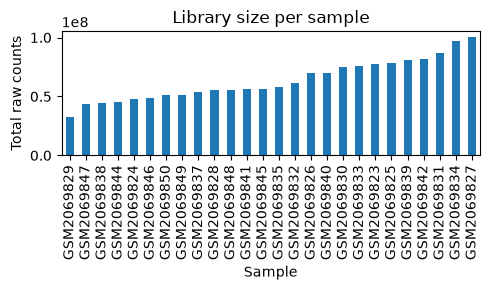

In [43]:
fig, ax = plt.subplots(figsize=(5, 3))
qc.sort_values("library_size")["library_size"].plot.bar(ax=ax)
ax.set_ylabel("Total raw counts")
ax.set_xlabel("Sample")
ax.set_title("Library size per sample")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

- Library sizes span approximately 32M–100M raw counts across the 26 retained samples.
- The variation is mainly a difference in sequencing depth rather than a clear response-group pattern.
- Interpretation: the depth range is considerable, all samples are kept as DESeq2 size-factor normalization accounts for differences in sequencing depth.

### Number of detected genes per sample

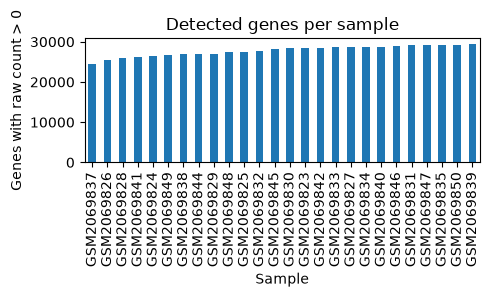

In [38]:
fig, ax = plt.subplots(figsize=(5,3))
qc.sort_values("detected_genes")["detected_genes"].plot.bar(ax=ax)
ax.set_ylabel("Genes with raw count > 0")
ax.set_xlabel("Sample")
ax.set_title("Detected genes per sample")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

- Detected genes range from around 24,000 to 30,000 per sample, with most samples near the upper end of this range.
- GSM2069837 has the lowest detected-gene count (~24.4k), but its library size is ~53 M, so low depth alone does not explain the reduction.
- there is some biological/technical heterogeneity in gene detection, but no obvious low-complexity sample is apparent from this metric alone.

### Sample-sample correlation

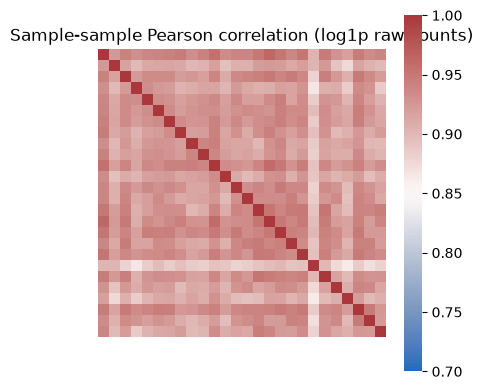

In [39]:
# log1p transformation limits domination by a small number of highly abundant genes.
# Correlation is used here as a QC diagnostic, not as an inferential test.
log_counts = np.log1p(counts)
sample_corr = log_counts.corr(method="pearson")

plt.figure(figsize=(4, 4))
sns.heatmap(sample_corr, cmap="vlag", vmin=0.7, vmax=1.0, square=True, xticklabels=False, yticklabels=False)
plt.title("Sample-sample Pearson correlation (log1p raw counts)")
plt.tight_layout()
plt.show()

- Samples show generally high pairwise Pearson correlations on log1p-transformed raw counts, with most of the heatmap in the high-correlation range.
- A small subset of samples is visibly less correlated with the remainder, but there is no broad block of samples indicating obvious widespread technical separation.
- the bulk expression profiles are broadly coherent.

### Count-depth distribution

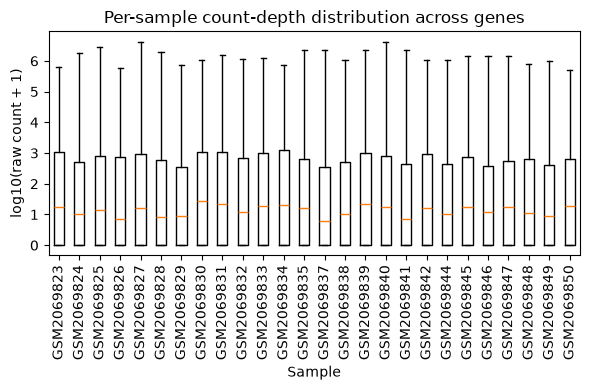

In [40]:
# Distribution of raw count depth across genes for each sample.
count_depth = [np.log10(counts[sample].to_numpy() + 1) for sample in counts.columns]
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(count_depth, showfliers=False)
ax.set_xticks(range(1, len(counts.columns) + 1))
ax.set_xticklabels(counts.columns, rotation=90)
ax.set_ylabel("log10(raw count + 1)")
ax.set_xlabel("Sample")
ax.set_title("Per-sample count-depth distribution across genes")
plt.tight_layout()
plt.show()

- Per-sample log10(raw count + 1) distributions are broadly similar in shape, with differences mainly in the median and upper tail reflecting variation in sequencing depth.
- The samples retain substantial overlap in their count-depth distributions, without a clearly isolated distribution that would indicate a severe library-level failure.
- the raw count distributions are compatible with proceeding to library-size normalization and DESeq2 modelling.

### 2. Differential Gene Expression Analysis

#### 2.1 loading and filtering the count matrix

In [41]:
counts.head()


,GSM2069823,GSM2069824,GSM2069825,GSM2069826,GSM2069827,GSM2069828,GSM2069829,GSM2069830,GSM2069831,GSM2069832,...,GSM2069840,GSM2069841,GSM2069842,GSM2069844,GSM2069845,GSM2069846,GSM2069847,GSM2069848,GSM2069849,GSM2069850
GeneID,,,,,,,,,,,,,,,,,,,,,
100287102,5,1,8,1,4,5,5,10,8,20,...,13,11,4,3,1,3,14,3,6,6
653635,852,394,1448,1476,1522,1291,655,1651,1541,638,...,970,1526,924,863,983,783,1028,762,822,1192
102466751,22,7,50,13,150,49,27,48,46,21,...,38,20,23,24,69,17,50,20,15,43
107985730,1,0,3,6,5,1,0,5,7,2,...,1,2,0,1,1,1,4,1,1,0
100302278,1,0,1,0,0,0,0,3,1,0,...,0,1,0,0,1,0,1,0,0,0


In [42]:
# Check that metadata and counts contain the same samples in the same order
assert len(meta) == 26
assert list(meta.index) == sample_ids
assert list(counts.columns) == sample_ids

print("Number of samples:", len(meta))
print("Sample order matches:", list(meta.index) == list(counts.columns))


Number of samples: 26
Sample order matches: True


In [43]:
# Check the GeneID index
assert counts.index.name == "GeneID"
assert counts.index.notna().all()
assert counts.index.is_unique

print("GeneID index is correct:", counts.index.name == "GeneID")
print("GeneIDs are unique:", counts.index.is_unique)


GeneID index is correct: True
GeneIDs are unique: True


In [44]:
# filter genes: keep genes with at least 10 counts in at least half of the samples
min_samples = int(np.ceil(len(sample_ids) / 2))
keep = (counts >= 10).sum(axis=1) >= min_samples

counts = counts.loc[keep].copy()

print(f"Genes before filtering: {keep.size:,}")
print(f"Genes after filtering: {counts.shape[0]:,}")
print(f"Genes removed: {(~keep).sum():,}")


Genes before filtering: 39,376
Genes after filtering: 19,988
Genes removed: 19,388


In [45]:
# Final checks after gene filtering
assert list(meta.index) == list(counts.columns)
assert counts.index.name == "GeneID"
assert counts.index.is_unique

print("Final counts shape:", counts.shape)
print("Final metadata shape:", meta.shape)
print("Samples in same order:", list(meta.index) == list(counts.columns))
print("First GeneIDs:", counts.index[:10].tolist())


Final counts shape: (19988, 26)
Final metadata shape: (26, 8)
Samples in same order: True
First GeneIDs: ['653635', '102466751', '100996442', '729737', '102723897', '102465909', '112268260', '100132287', '113219467', '100133331']


In [46]:
print(counts.shape)   # genes × samples
print(meta.shape)     # samples × metadata columns


(19988, 26)
(26, 8)


**Count-matrix objects**

- `counts_raw`: raw count file, kept unchanged.
- `counts`: analysis matrix, with `GeneID` as row index and the 26 filtered samples in the same order as `meta`.
- Gene filtering is applied to `counts`, not `counts_raw`.


#### 2.2 Build the DESeq2 object

In [47]:
counts_pd = counts.T

In [48]:
dds = DeseqDataSet(
    counts=counts_pd,
    metadata=meta,
    design="~response + previous_mapki"
)

In [49]:
dds.deseq2()

Fitting size factors...
... done in 0.03 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 2.61 seconds.

Fitting dispersion trend curve...
... done in 0.43 seconds.

Fitting MAP dispersions...
... done in 3.00 seconds.

Fitting LFCs...
... done in 2.03 seconds.

Calculating cook's distance...
... done in 0.04 seconds.

Replacing 957 outlier genes.

Fitting dispersions...
... done in 0.21 seconds.

Fitting MAP dispersions...
... done in 0.21 seconds.

Fitting LFCs...
... done in 0.22 seconds.



...DESeq2 output shows that Cook's-distance outlier handling replaced 957 genes during fitting

In [50]:
# variance stabilization
dds.vst()

Fit type used for VST : parametric
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.03 seconds.

Fitting dispersions...
... done in 2.73 seconds.



In [51]:
vst_counts=dds.layers["vst_counts"]

#### 2.3 PCA

In [52]:
dds.vst(use_design=False)
vst_counts=dds.layers["vst_counts"]

Fit type used for VST : parametric
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.03 seconds.

Fitting dispersions...
... done in 2.66 seconds.



In [53]:
# filter for top 500 most variable genes
gene_var = np.var(vst_counts, axis=0)

top_idx = np.argsort(gene_var)[-500:]
vst_top = vst_counts[:, top_idx]

In [54]:
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(vst_top)

In [55]:
pca_df = pd.DataFrame(
    pca_coords,
    index=meta.index,
    columns=["PC1", "PC2"]
).join(meta)

In [56]:
pca_df.head()

,PC1,PC2,patient,response,sex,age,disease_status,vital_status,previous_mapki,biopsy_time
sample,,,,,,,,,,
GSM2069823,31.857793,-10.763348,Pt1,non-responder,F,66,M1b,Dead,N,pre-treatment
GSM2069824,-19.501683,-19.373972,Pt2,responder,M,55,M1c,Alive,N,pre-treatment
GSM2069825,17.632629,9.174919,Pt4,responder,M,62,M1c,Alive,Y,pre-treatment
GSM2069826,-45.633068,34.896333,Pt5,responder,M,61,M1c,Alive,N,pre-treatment
GSM2069827,-39.822524,32.385500,Pt6,responder,M,51,M1c,Alive,Y,pre-treatment


In [57]:
# get explained variance
pca.explained_variance_ratio_
pc1_var, pc2_var = pca.explained_variance_ratio_[:2]*100

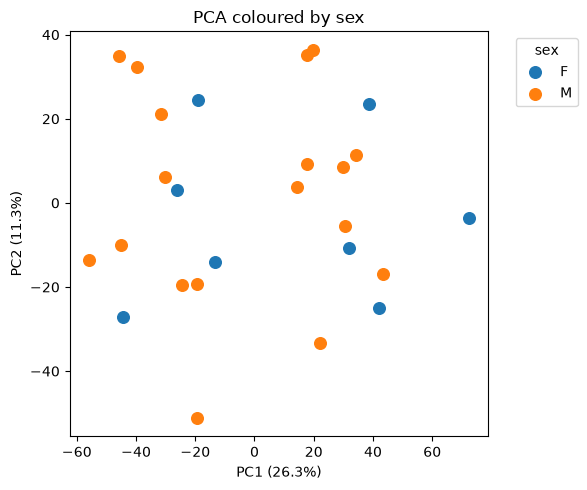

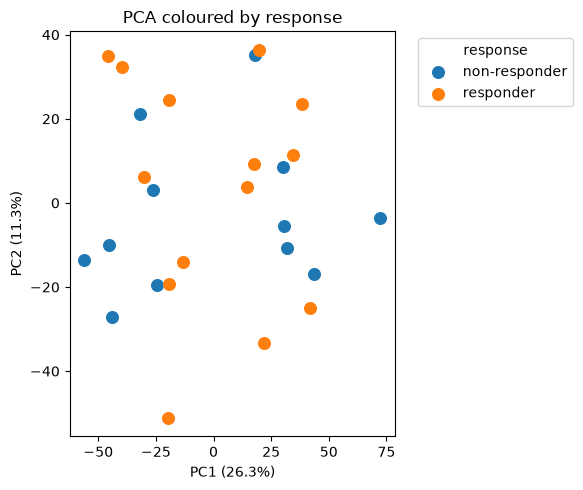

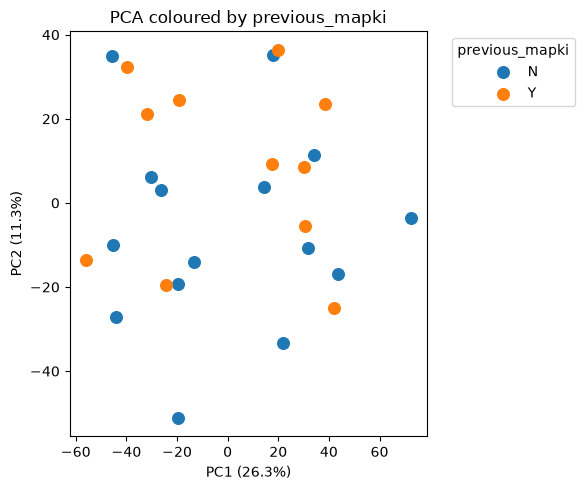

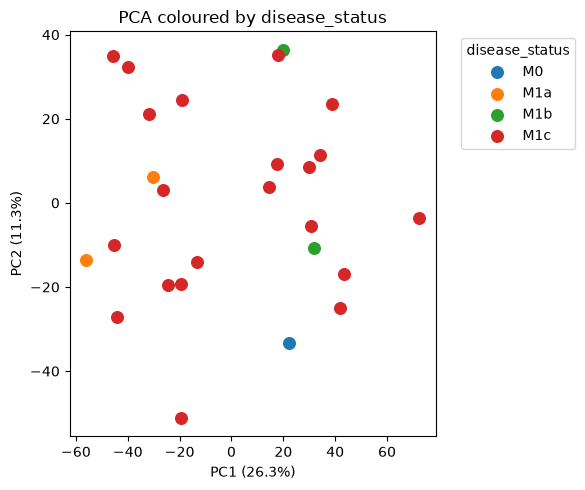

In [58]:
group_vars = ["sex", "response", "previous_mapki", "disease_status"]

for var in group_vars:
    fig, ax = plt.subplots(figsize=(6, 5))

    for group, df_group in pca_df.groupby(var):
        ax.scatter(
            df_group["PC1"],
            df_group["PC2"],
            label=group,
            s=70
        )

    ax.set_title(f"PCA coloured by {var}")
    ax.set_xlabel(f"PC1 ({pc1_var:.1f}%)")
    ax.set_ylabel(f"PC2 ({pc2_var:.1f}%)")
    ax.legend(title=var, bbox_to_anchor=(1.05, 1), loc="upper left")

    plt.tight_layout()
    if var == "response":
        fig.savefig(FIGURE_DIR / "pca_response.pdf", bbox_inches="tight")
    plt.show()


- PCA was performed on variance-stabilized (vst) expression values from the 500 most variable genes
- PC1 explains 26.3% and PC2 11.3% of the total variance
- no clear separation of sampels by sex --> sex not a major source of variation
- by response: no distinct clustering
- previous MAPK-inhibitor exposure and disease status also did not produce obvious discrete sample clusters in PC1/PC2 space.

--> The first two principal components do not show strong separation of the major clinical groups examined.

#### 2.4 DEG summary

In [59]:
stat_res = DeseqStats(
    dds,
    contrast=("response", "responder", "non-responder")
)

stat_res.summary()

res = stat_res.results_df.copy()
res.head()

Running Wald tests...


Log2 fold change & Wald test p-value: response responder vs non-responder
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
GeneID                                                                   
653635       1102.935557        0.116732  0.229248  0.509197  0.610614   
102466751      38.303275        0.148099  0.339622  0.436071  0.662785   
100996442      73.807657        0.363981  0.241084  1.509771  0.131102   
729737        383.011640        0.101390  0.401030  0.252824  0.800404   
102723897    1278.521104        0.171021  0.230544  0.741818  0.458197   
...                  ...             ...       ...       ...       ...   
4541       172958.249150        0.167275  0.465038  0.359701  0.719071   
4556        11620.548940       -0.011929  0.453479 -0.026306  0.979013   
4519       486608.946421        0.159191  0.475908  0.334499  0.738003   
4576          962.886109       -0.017005  0.570068 -0.029830  0.976203   
4571         7786.533529       -0.0449

... done in 1.19 seconds.



,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
GeneID,,,,,,
653635,1102.935557,0.116732,0.229248,0.509197,0.610614,0.933934
102466751,38.303275,0.148099,0.339622,0.436071,0.662785,0.947632
100996442,73.807657,0.363981,0.241084,1.509771,0.131102,0.657210
729737,383.011640,0.101390,0.401030,0.252824,0.800404,0.971770
102723897,1278.521104,0.171021,0.230544,0.741818,0.458197,0.886409


In [60]:
# clean results
res = (
    res
    .dropna(subset=["padj"])
    .sort_values("padj")
)

res["contrast"] = "responder/non_responder"
res["gene"] = res.index

In [61]:
# Convert Entrez IDs to gene symbols
# !pip instal mygene
import mygene

In [62]:
# --- 1. Inspect the IDs ------------------------------------------
gene_ids = res.index.astype(str)

print("First 5 IDs:", gene_ids[:5].tolist())

# Detect Ensembl IDs
if gene_ids.str.startswith("ENSG").all():
    scope = "ensembl.gene"
    # Remove version numbers (ENSG... .15 -> ENSG...)
    gene_ids = gene_ids.str.replace(r"\..*$", "", regex=True)
else:
    scope = "entrezgene"

print("Using scope:", scope)

# --- 2. Query MyGene ---------------------------------------------
mg = mygene.MyGeneInfo()

gene_info = mg.querymany(
    gene_ids.tolist(),
    scopes=scope,
    fields="symbol",
    species="human",
    as_dataframe=True
)

# --- 3. Build mapping --------------------------------------------
id_to_symbol = (
    gene_info["symbol"]
    .dropna()
    .to_dict()
)

# Use the cleaned IDs for mapping
res["gene_id"] = gene_ids.values
res["symbol"] = res["gene_id"].map(id_to_symbol)

# --- 4. Quality check --------------------------------------------
print(f"Mapped: {res['symbol'].notna().sum()} / {len(res)} genes")
print("\nUnmapped examples:")
print(res.loc[res["symbol"].isna(), "gene_id"].head(10))

# --- 5. Keep gene ID only as fallback -----------------------------
res["symbol"] = res["symbol"].fillna(res["gene_id"])

First 5 IDs: ['3854', '81501', '229', '57687', '101928143']
Using scope: entrezgene


427 input query terms found no hit:	['112268463', '107987259', '102724889', '105379508', '107985041', '107984849', '84953', '107986257',


Mapped: 19004 / 19431 genes

Unmapped examples:
GeneID
112268463    112268463
107987259    107987259
102724889    102724889
105379508    105379508
107985041    107985041
107984849    107984849
84953            84953
107986257    107986257
112268202    112268202
107986114    107986114
Name: gene_id, dtype: str


In [63]:
print(res.index.dtype)
print(res.index[:20].tolist())
print(res.index.astype(str).str.match(r"^\d+$").mean())

str
['3854', '81501', '229', '57687', '101928143', '1404', '2303', '1298', '9457', '160428', '2006', '65997', '374946', '55966', '27122', '107986809', '2300', '133396', '7143', '6585']
1.0


In [64]:
# mg = mygene.MyGeneInfo()

# gene_info = mg.querymany(
#     res.index.astype(str).tolist(),
#     scopes="entrezgene",
#     fields="symbol",
#     species="human",
#     as_dataframe=True
# )

print(gene_info.head())
print(gene_info.columns)
print(gene_info.index[:10])


                 _id     _score        symbol notfound
query                                                 
3854            3854  27.427767         KRT6B      NaN
81501          81501  27.427767       DCSTAMP      NaN
229              229  27.427767         ALDOB      NaN
57687          57687  27.427767         VAT1L      NaN
101928143  101928143  27.427767  LOC101928143      NaN
Index(['_id', '_score', 'symbol', 'notfound'], dtype='str')
Index(['3854', '81501', '229', '57687', '101928143', '1404', '2303', '1298',
       '9457', '160428'],
      dtype='str', name='query')


In [65]:
print(res.index[:30].tolist())
print(res.index.astype(str).str.startswith("ENSG").sum())
print(res.index.astype(str).str.fullmatch(r"\d+").sum())

['3854', '81501', '229', '57687', '101928143', '1404', '2303', '1298', '9457', '160428', '2006', '65997', '374946', '55966', '27122', '107986809', '2300', '133396', '7143', '6585', '10234', '6817', '999', '547', '3624', '8614', '2199', '8325', '23130', '64220']
0
19431


In [79]:
print(res.index[:50].tolist())
print(res.shape)
print(res.index.min())
print(res.index.max())
print(res.head())

['3854', '81501', '229', '57687', '101928143', '1404', '2303', '1298', '9457', '160428', '2006', '65997', '374946', '55966', '27122', '107986809', '2300', '133396', '7143', '6585', '10234', '6817', '999', '547', '3624', '8614', '2199', '8325', '23130', '64220', '51599', '23284', '147920', '81832', '105376806', '102724339', '2259', '400999', '102725509', '55273', '143903', '51761', '107987299', '80760', '7757', '101927229', '3778', '101927727', '3175', '130497']
(19431, 10)
1
9997
               baseMean  log2FoldChange     lfcSE       stat        pvalue  \
GeneID                                                                       
3854       17649.463474       21.552936  1.898773  11.350983  7.333327e-30   
81501        647.802939       -5.451943  0.820931  -6.641175  3.111928e-11   
229         4498.656738       23.408400  3.703229   6.321077  2.597460e-10   
57687       1491.518790       -5.540255  0.882263  -6.279594  3.394578e-10   
101928143    116.201146       -4.301946  0.7281

In [66]:
print(counts.shape)

print("First 20 row names:")
print(counts.index[:20].tolist())

print("Index type:")
print(counts.index.dtype)

print("Unique row names:")
print(counts.index.is_unique)

print("First 20 columns:")
print(counts.columns[:20].tolist())

(19988, 26)
First 20 row names:
['653635', '102466751', '100996442', '729737', '102723897', '102465909', '112268260', '100132287', '113219467', '100133331', '107984841', '107984847', '107984849', '100288069', '105378580', '400728', '79854', '643837', '148398', '26155']
Index type:
str
Unique row names:
True
First 20 columns:
['GSM2069823', 'GSM2069824', 'GSM2069825', 'GSM2069826', 'GSM2069827', 'GSM2069828', 'GSM2069829', 'GSM2069830', 'GSM2069831', 'GSM2069832', 'GSM2069833', 'GSM2069834', 'GSM2069835', 'GSM2069837', 'GSM2069838', 'GSM2069839', 'GSM2069840', 'GSM2069841', 'GSM2069842', 'GSM2069844']


In [67]:
print("ORIGINAL")
print(counts_raw.shape)
print(counts_raw.index[:20].tolist())

print("\nFILTERED")
print(counts.shape)
print(counts.index[:20].tolist())

ORIGINAL
(39376, 29)
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

FILTERED
(19988, 26)
['653635', '102466751', '100996442', '729737', '102723897', '102465909', '112268260', '100132287', '113219467', '100133331', '107984841', '107984847', '107984849', '100288069', '105378580', '400728', '79854', '643837', '148398', '26155']


In [68]:
# mapping: Entrez ID -> symbol
id_to_symbol = gene_info["symbol"].dropna().to_dict()

# Add symbols
res["symbol"] = res.index.astype(str).map(id_to_symbol)

# Use Entrez ID if no symbol was found
res["symbol"] = res["symbol"].fillna(
    pd.Series(res.index.astype(str), index=res.index)
)

In [69]:
# filter for significant genes
padj_cutoff = 0.05
fc_cutoff = 1.5
lfc_cutoff = np.log2(fc_cutoff)

res["regulation"] = "ns"

res.loc[
    (res["padj"] < padj_cutoff) &
    (res["log2FoldChange"] >= lfc_cutoff),
    "regulation"
] = "up"


res.loc[
    (res["padj"] < padj_cutoff) &
    (res["log2FoldChange"] <= -lfc_cutoff),
    "regulation"
] = "down"

res["regulation"].value_counts()

res.to_csv(TABLE_DIR / "deseq2_responder_vs_nonresponder.csv", index=False)
res.query("regulation != 'ns'").to_csv(TABLE_DIR / "deseq2_significant_degs.csv", index=False)


##### number of DEGs

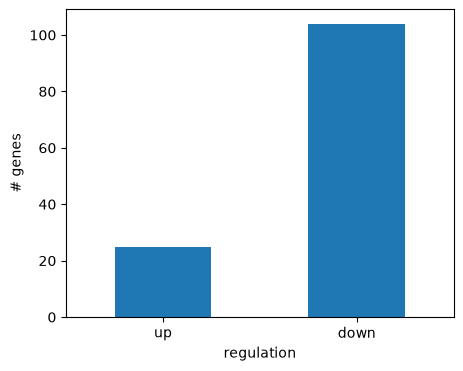

In [70]:
summary = (
    res["regulation"]
    .value_counts()
    .reindex(["up","down"]) # "ns"
    .fillna(0)
)

summary.plot.bar(figsize=(5,4))
plt.ylabel("# genes")
plt.xticks(rotation=0)
plt.show()

- DGE was evaluated for **responders versus non-responder**s using a DESeq2 Wald test while adjusting for previous MAPK-inhibitor treatment.
- 104 genes were identified as down- and 25 genes as up-regulated with statistically significant differential expression after multiple-testing correction.
- significance thresholds were set to adjusted P < 0.05 and |log2FC| > log2(1.5)


##### Volcano plot

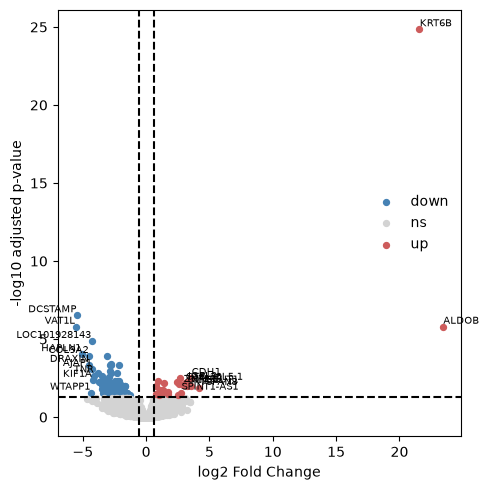

In [72]:
res["neglog10"] = -np.log10(res["padj"])
res = res.copy()
res["GeneID"] = res.index

colors = {
    "up":"indianred",
    "down":"steelblue",
    "ns":"lightgrey"
}

fig, ax = plt.subplots(figsize=(5,5))

# scatter points
for label, df in res.groupby("regulation"):
    ax.scatter(
        df["log2FoldChange"],
        df["neglog10"],
        c=colors[label],
        s=18,
        label=label
    )

# thresholds
ax.axvline(np.log2(1.5), ls="--", c="black")
ax.axvline(-np.log2(1.5), ls="--", c="black")
ax.axhline(-np.log10(0.05), ls="--", c="black")

# Top 10 up and down by log2FC
res["mean"] = np.log10(res["baseMean"] + 1)

top_up = (
    res[res["regulation"] == "up"]
    .nlargest(10, "log2FoldChange")
)

top_down = (
    res[res["regulation"] == "down"]
    .nsmallest(10, "log2FoldChange")
)

# Add labels
for _, row in pd.concat([top_up, top_down]).iterrows():
    ax.text(
        row["log2FoldChange"] + (0.05 if row["log2FoldChange"] > 0 else -0.05),
        row["neglog10"] + 0.05,
        row["symbol"],
        fontsize=7,
        ha="left" if row["log2FoldChange"] > 0 else "right",
        va="bottom"
    )

ax.set_xlabel("log2 Fold Change")
ax.set_ylabel("-log10 adjusted p-value")
ax.legend(frameon=False)

plt.tight_layout()
fig.savefig(FIGURE_DIR / "volcano_responder_vs_nonresponder.pdf", bbox_inches="tight")
plt.show()

##### MA plot

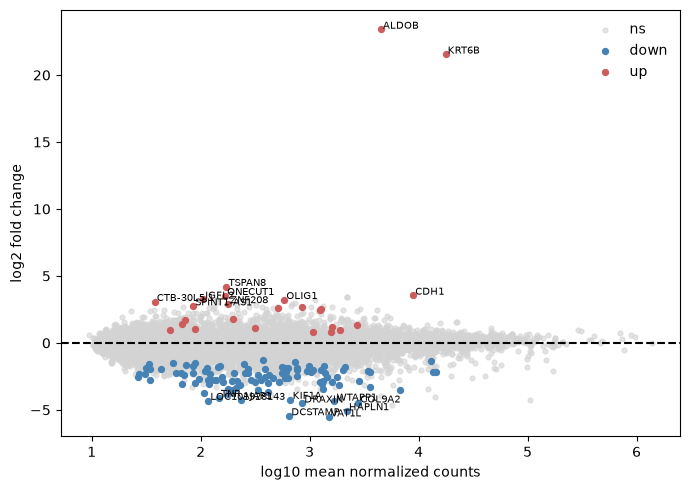

In [73]:
res["mean"] = np.log10(res["baseMean"] + 1)

fig, ax = plt.subplots(figsize=(7, 5))

# 1. Background: non-significant
ns = res[res["regulation"] == "ns"]
ax.scatter(
    ns["mean"], ns["log2FoldChange"],
    c=colors["ns"], s=12, alpha=0.6,
    label="ns", zorder=1
)

# 2. Foreground: significant genes
for reg in ["down", "up"]:
    df = res[res["regulation"] == reg]
    ax.scatter(
        df["mean"], df["log2FoldChange"],
        c=colors[reg], s=18,
        label=reg, zorder=2
    )

# Labels on top
for _, row in pd.concat([top_up, top_down]).iterrows():
    ax.text(
        row["mean"] + 0.02,
        row["log2FoldChange"] + 0.05,
        row["symbol"],
        fontsize=7,
        zorder=3
    )

ax.axhline(0, color="black", ls="--")
ax.set_xlabel("log10 mean normalized counts")
ax.set_ylabel("log2 fold change")
ax.legend(frameon=False)

plt.tight_layout()
fig.savefig(FIGURE_DIR / "ma_responder_vs_nonresponder.pdf", bbox_inches="tight")
plt.show()

##### Heatmaps

In [74]:
res

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,contrast,gene,gene_id,symbol,regulation,neglog10,GeneID,mean
GeneID,,,,,,,,,,,,,,
3854,17649.463474,2.155294e+01,1.898773,11.350983,7.333327e-30,1.424939e-25,responder/non_responder,3854,3854,KRT6B,up,2.484620e+01,3854,4.246756
81501,647.802939,-5.451943e+00,0.820931,-6.641175,3.111928e-11,3.023394e-07,responder/non_responder,81501,81501,DCSTAMP,down,6.519505e+00,81501,2.812113
229,4498.656738,2.340840e+01,3.703229,6.321077,2.597460e-10,1.649001e-06,responder/non_responder,229,229,ALDOB,up,5.782779e+00,229,3.653179
57687,1491.518790,-5.540255e+00,0.882263,-6.279594,3.394578e-10,1.649001e-06,responder/non_responder,57687,57687,VAT1L,down,5.782779e+00,57687,3.173920
101928143,116.201146,-4.301946e+00,0.728113,-5.908348,3.455563e-09,1.342901e-05,responder/non_responder,101928143,101928143,LOC101928143,down,4.871956e+00,101928143,2.068932
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
219541,822.849367,1.827718e-04,0.273449,0.000668,9.994667e-01,9.997794e-01,responder/non_responder,219541,219541,MED19,ns,9.582747e-05,219541,2.915848
51079,10577.522729,-1.280610e-04,0.338119,-0.000379,9.996978e-01,9.998214e-01,responder/non_responder,51079,51079,NDUFA13,ns,7.756097e-05,51079,4.024425
107984958,37.318953,2.097017e-04,0.666375,0.000315,9.997489e-01,9.998214e-01,responder/non_responder,107984958,107984958,DHCR24-DT,ns,7.756097e-05,107984958,1.583414


In [75]:
meta

,patient,response,sex,age,disease_status,vital_status,previous_mapki,biopsy_time
sample,,,,,,,,
GSM2069823,Pt1,non-responder,F,66,M1b,Dead,N,pre-treatment
GSM2069824,Pt2,responder,M,55,M1c,Alive,N,pre-treatment
GSM2069825,Pt4,responder,M,62,M1c,Alive,Y,pre-treatment
GSM2069826,Pt5,responder,M,61,M1c,Alive,N,pre-treatment
GSM2069827,Pt6,responder,M,51,M1c,Alive,Y,pre-treatment
GSM2069828,Pt7,non-responder,F,55,M1c,Dead,N,pre-treatment
GSM2069829,Pt8,responder,M,69,M1a,Alive,N,pre-treatment
GSM2069830,Pt9,responder,M,68,M0,Alive,N,pre-treatment
GSM2069831,Pt10,non-responder,M,60,M1a,Alive,Y,pre-treatment


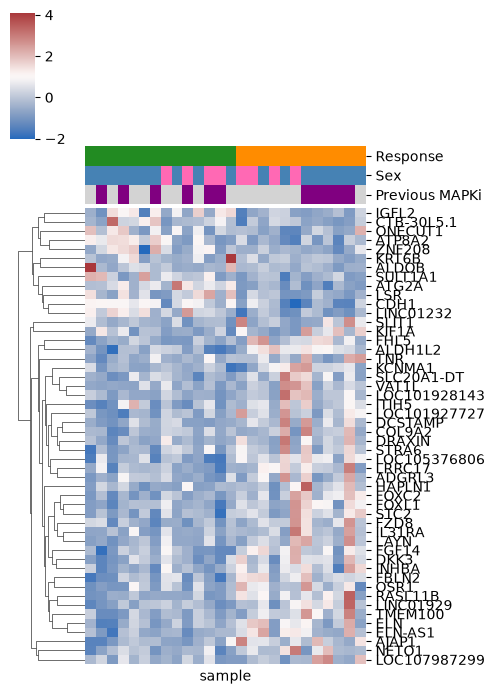

In [76]:
# Top 50 significant genes
top_res = (
    res.query("padj < 0.05")
       .sort_values("padj")
       .head(50)
)

top_genes = top_res.index

# VST matrix
heatmap_data = pd.DataFrame(
    dds.layers["vst_counts"].T,
    index=dds.var_names,
    columns=dds.obs_names
).loc[top_genes]

# Replace Entrez IDs with gene symbols
heatmap_data.index = top_res["symbol"].values

# Z-score by gene
heatmap_data = heatmap_data.sub(
    heatmap_data.mean(axis=1), axis=0
).div(
    heatmap_data.std(axis=1), axis=0
)

# Sample annotation
# col_colors = meta["response"].map({
#     "responder": "green",
#     "non-responder": "orange"
# })

# Create a color map for each metadata variable
response_colors = meta["response"].map({
    "responder": "forestgreen",
    "non-responder": "darkorange"
})

sex_colors = meta["sex"].map({
    "M": "steelblue",
    "F": "hotpink"
})

mapki_colors = meta["previous_mapki"].map({
    "Y": "purple",
    "N": "lightgray"
})

# Combine into one DataFrame
col_colors = pd.DataFrame({
    "Response": response_colors,
    "Sex": sex_colors,
    "Previous MAPKi": mapki_colors
}, index=meta.index)

# Order samples: responders first
sample_order = (
    meta.sort_values("response", key=lambda s: s.map({
        "responder": 0,
        "non-responder": 1
    }))
    .index
)

# Reorder heatmap and annotations
heatmap_data = heatmap_data[sample_order]
col_colors = col_colors.loc[sample_order]

g = sns.clustermap(
    heatmap_data,
    cmap="vlag",
    col_colors=col_colors,
    figsize=(5, 7),
    xticklabels=False,
    yticklabels=True,
    col_cluster=False
)
g.savefig(FIGURE_DIR / "heatmap_top50_degs.pdf", bbox_inches="tight")


## 3.1 Over-representation Analysis (ORA)

In [77]:
import gseapy as gp

In [78]:
all_sig = res.query("padj < 0.05")["symbol"].tolist()

gene_sets = ["GO_Biological_Process_2026", 
               "GO_Cellular_Component_2026",
               "GO_Molecular_Function_2026",
               "KEGG_2026",
               "WikiPathways_2024_Human"
               ]

# Store results
ora_results = []

for gs in gene_sets:
    ora = gp.enrichr(
        gene_list=all_sig,
        gene_sets=gs,
        organism="human",
        outdir=None
    )

    df = ora.results.copy()
    df["Gene_set"] = gs      # keep track of the source
    ora_results.append(df)

# Combine into one dataframe
final_ora = pd.concat(ora_results, ignore_index=True)

print(final_ora.head())

final_ora.to_csv(TABLE_DIR / "ora_results.csv", index=False)


                     Gene_set  \
0  GO_Biological_Process_2026   
1  GO_Biological_Process_2026   
2  GO_Biological_Process_2026   
3  GO_Biological_Process_2026   
4  GO_Biological_Process_2026   

                                                Term Overlap   P-value  \
0           Skeletal System Development (GO:0001501)   8/169  0.000014   
1  Establishment of Blood-Brain Barrier (GO:0060856)     2/5  0.000408   
2  Regulation of Renal Sodium Excretion (GO:0035813)     2/6  0.000609   
3                    Kidney Development (GO:0001822)    4/72  0.001211   
4  Negative Regulation of Heterotypic Cell-Cell A...     2/9  0.001443   

   Adjusted P-value  Old P-value  Old Adjusted P-value  Odds Ratio  \
0          0.012798            0                     0    8.094040   
1          0.183595            0                     0  104.293963   
2          0.183595            0                     0   78.216535   
3          0.183595            0                     0    9.319059   
4     

In [79]:
final_ora[final_ora["Adjusted P-value"] < 0.05]

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2026,Skeletal System Development (GO:0001501),8/169,0.000014,0.012798,0,0,8.094040,90.408075,COMP;ACAN;VCAN;BGLAP;OGN;ALX4;COL9A2;HAPLN1
908,GO_Cellular_Component_2026,Microfibril (GO:0001527),4/17,0.000004,0.000153,0,0,48.881231,611.585755,MFAP4;VCAN;MFAP2;FBLN2
909,GO_Cellular_Component_2026,Golgi Lumen (GO:0005796),7/102,0.000004,0.000153,0,0,11.944090,147.373920,ACAN;VCAN;CDH1;BGLAP;LUM;OMD;OGN
910,GO_Cellular_Component_2026,Elastic Fiber (GO:0071953),5/40,0.000006,0.000153,0,0,22.852535,276.068364,MFAP4;VCAN;ELN;MFAP2;FBLN2
911,GO_Cellular_Component_2026,Perineuronal Net (GO:0072534),3/8,0.000014,0.000290,0,0,94.600000,1055.041872,ACAN;VCAN;HAPLN1
912,GO_Cellular_Component_2026,Perisynaptic Extracellular Matrix (GO:0098966),3/9,0.000021,0.000347,0,0,78.829365,847.567311,ACAN;VCAN;HAPLN1
913,GO_Cellular_Component_2026,Supramolecular Fiber (GO:0099512),5/64,0.000058,0.000784,0,0,13.540186,132.073836,MFAP4;VCAN;ELN;MFAP2;FBLN2
914,GO_Cellular_Component_2026,Lysosomal Lumen (GO:0043202),5/91,0.000308,0.003566,0,0,9.276538,74.998764,ACAN;VCAN;LUM;OMD;OGN
915,GO_Cellular_Component_2026,Vacuolar Lumen (GO:0005775),5/167,0.004581,0.046384,0,0,4.905665,26.420985,ACAN;VCAN;LUM;OMD;OGN
1137,KEGG_2026,ECM-RECEPTOR INTERACTION,5/88,0.000264,0.033748,0,0,9.613292,79.221941,COMP;LAMA2;ITGA8;TNR;COL9A2


In [80]:
# gp.dotplot(
#     final_ora,
#     figsize=(5,3),
#     title="GO enrichment (Upregulated)"
# )

## 3.2 Gene-set enrichment Analysis (GSEA)

In [81]:
# create ranking
ranking = (
    res[["symbol","log2FoldChange"]]
    .dropna()
    .sort_values("log2FoldChange", ascending=False)
)

ranking.head()


,symbol,log2FoldChange
GeneID,,
229,ALDOB,23.408400
3854,KRT6B,21.552936
7103,TSPAN8,4.203732
999,CDH1,3.548332
3175,ONECUT1,3.527075


In [82]:
gsea = gp.prerank(
    rnk=ranking,
    gene_sets="MSigDB_Hallmark_2020",
    permutation_num=1000,
    outdir=None,
    seed=42
)

gsea.res2d.to_csv(TABLE_DIR / "gsea_hallmark_results.csv", index=False)


2026-09-30 06:43:07,940 [WARNING] Duplicated values found in preranked stats: 0.02% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


In [83]:
gsea.res2d.head()

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,Epithelial Mesenchymal Transition,-0.722665,-2.642800,0.000000,0.000000,0.000,127/192,16.67%,MMP1;INHBA;FOXC2;COMP;CRLF1;ELN;FZD8;VCAN;GPC1...
1,prerank,Oxidative Phosphorylation,0.462876,1.888562,0.000000,0.080732,0.047,115/197,38.38%,ACADSB;ALDH6A1;ATP1B1;MAOB;NDUFC1;SLC25A4;SLC2...
2,prerank,UV Response Dn,-0.507583,-1.813301,0.000000,0.002485,0.006,56/143,22.03%,COL11A1;PTGFR;LTBP1;KCNMA1;COL5A2;MMP16;IGFBP5...
3,prerank,KRAS Signaling Up,-0.484611,-1.766232,0.000000,0.004418,0.016,54/167,15.72%,INHBA;TMEM100;LIF;ITGBL1;ALDH1A3;ALDH1A2;CPE;P...
4,prerank,Angiogenesis,-0.620395,-1.707011,0.004608,0.007041,0.034,12/29,10.16%,STC1;VCAN;LUM;COL5A2;S100A4;NRP1;FGFR1;COL3A1;...


In [84]:
# Get the top 5 pathway names by FDR
terms = (
    gsea.res2d
    .sort_values("FDR q-val")["Term"]
    .head(10)
    .tolist()
)

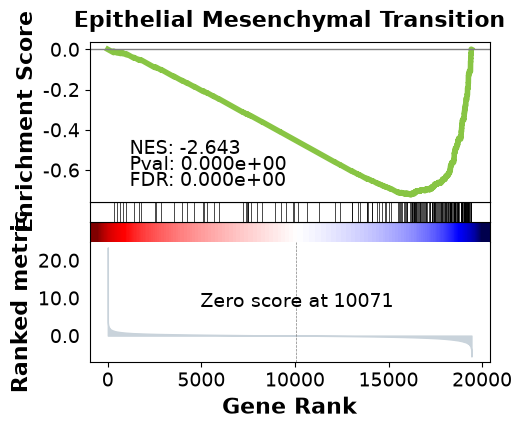

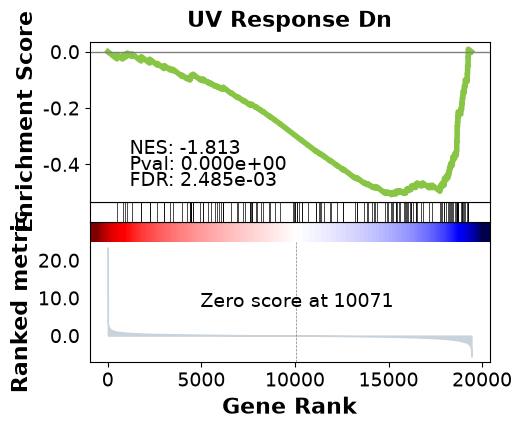

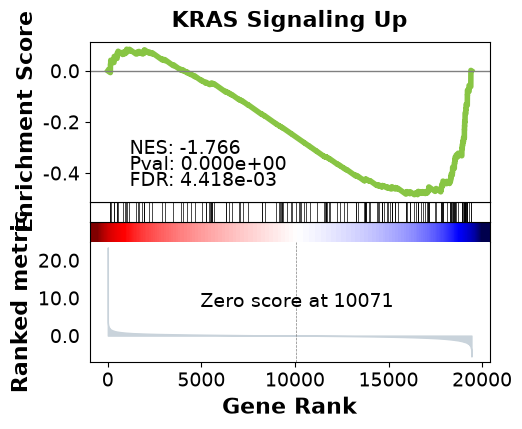

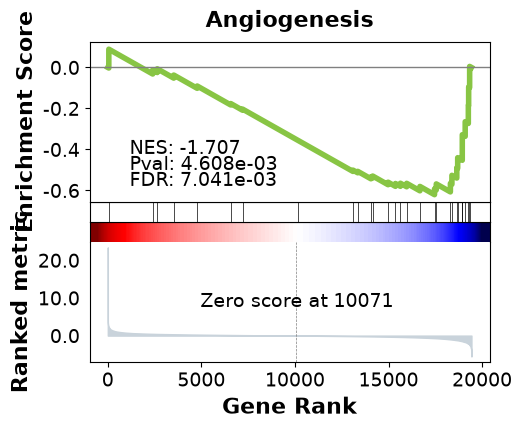

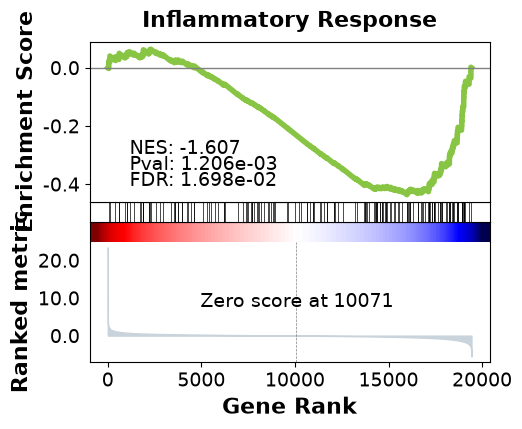

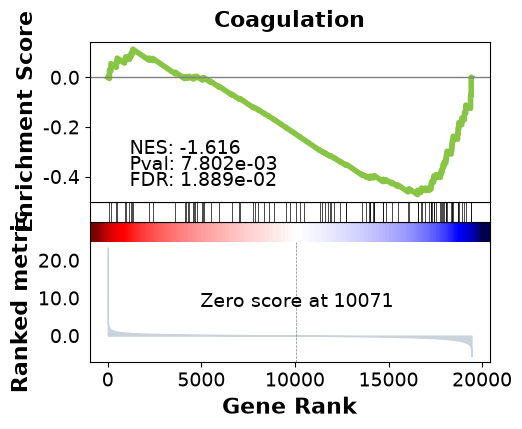

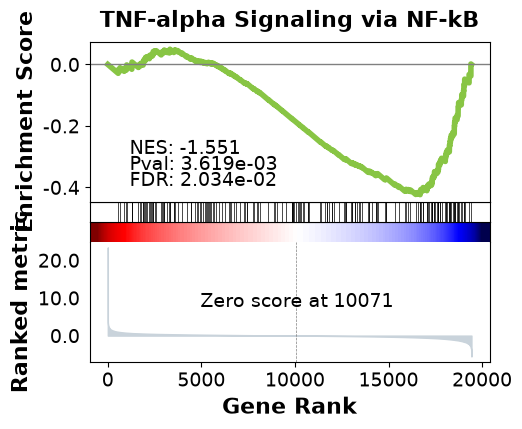

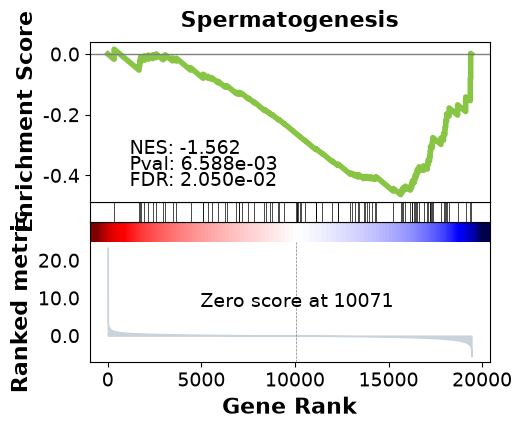

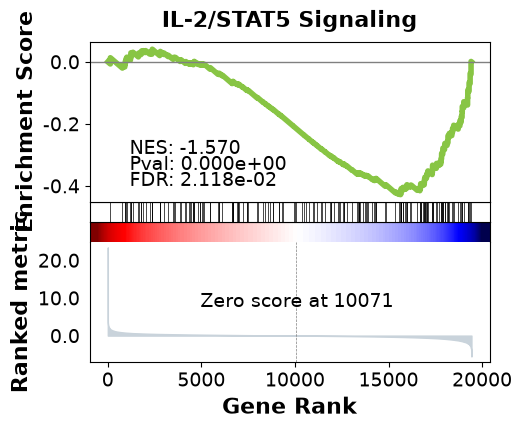

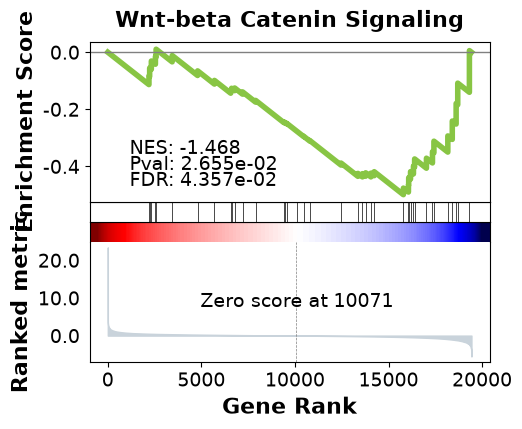

In [85]:
for i, term in enumerate(terms):
    gp.gseaplot(
        rank_metric=gsea.ranking,
        term=term,
        **gsea.results[term],
        figsize=(5, 4)
    )
    if i < 3:
        safe_term = term.lower().replace(" ", "_").replace("/", "-")
        plt.gcf().savefig(FIGURE_DIR / f"gsea_{i+1:02d}_{safe_term}.pdf", bbox_inches="tight")

In [86]:
terms

['Epithelial Mesenchymal Transition',
 'UV Response Dn',
 'KRAS Signaling Up',
 'Angiogenesis',
 'Inflammatory Response',
 'Coagulation',
 'TNF-alpha Signaling via NF-kB',
 'Spermatogenesis',
 'IL-2/STAT5 Signaling',
 'Wnt-beta Catenin Signaling']

## Validation against the literature

The original GSE78220 study (Hugo et al., *Cell*, 2016; PMID 26997480) reported an innate anti-PD-1 resistance (IPRES) transcriptional program in non-responding tumors. The main reported processes included mesenchymal transition, cell adhesion / extracellular-matrix organization, angiogenesis, and wound healing. The comparison below asks whether the present reanalysis recovers the same direction of pathway-level biology.

Because the DESeq2 contrast is `responder / non-responder`, a negative GSEA NES indicates enrichment toward non-responders. Therefore, negative NES values for IPRES-related pathways are directionally concordant with the published study.

In [87]:
# Targeted literature-validation table using the already-computed Hallmark GSEA results.
ipres_keywords = {
    "epithelial_mesenchymal_transition": ["EPITHELIAL MESENCHYMAL TRANSITION"],
    "angiogenesis": ["ANGIOGENESIS"],
    "hypoxia": ["HYPOXIA"],
    "inflammatory_response": ["INFLAMMATORY RESPONSE"]
}
gsea_validation = gsea.res2d.copy()
gsea_validation["Term_normalized"] = (
    gsea_validation["Term"].astype(str)
    .str.upper()
    .str.replace(r"[^A-Z0-9]+", " ", regex=True)
    .str.strip()
)
rows = []
for process, keywords in ipres_keywords.items():
    hit = gsea_validation[
        gsea_validation["Term_normalized"].apply(lambda x: any(k in x for k in keywords))
    ].copy()
    if not hit.empty:
        hit = hit.sort_values("FDR q-val").iloc[0]
        nes = pd.to_numeric(hit["NES"])
        rows.append({
            "published_process": process,
            "matched_gene_set": hit["Term"],
            "NES": nes,
            "FDR_q_value": pd.to_numeric(hit["FDR q-val"]),
            "enriched_toward": "non-responder" if nes < 0 else "responder",
            "directionally_consistent_with_IPRES": bool(nes < 0)
        })
literature_validation = pd.DataFrame(rows)
literature_validation

literature_validation.to_csv(TABLE_DIR / "literature_validation_gsea.csv", index=False)


In [88]:
# Complement the Hallmark check with ORA terms containing key IPRES concepts.
ipres_pattern = r"mesench|extracellular matrix|ECM|adhesion|angiogen|wound|vascul|hypoxi"
ora_ipres = (
    final_ora[final_ora["Term"].astype(str).str.contains(ipres_pattern, case=False, regex=True, na=False)]
    .sort_values("Adjusted P-value")
    [["Gene_set", "Term", "Adjusted P-value", "Overlap", "Genes"]]
    .head(20)
)
ora_ipres

ora_ipres.to_csv(TABLE_DIR / "literature_validation_ora.csv", index=False)


### Interpretation of the literature comparison

This analysis shows pathway-level concordance with the published IPRES phenotype. Hugo *et al*. reported that tumors with innate anti-PD-1 resistance showed coordinated upregulation of programs involving mesenchymal transition, cell adhesion / extracellular-matrix (ECM) remodeling, angiogenesis, and wound healing.

In the present responder-versus-non-responder contrast, negative NES values indicate enrichment in non-responders. The strongest Hallmark GSEA result is Epithelial Mesenchymal Transition (NES = -2.64, FDR q-value < 0.001), with Angiogenesis also significantly enriched in non-responders (NES = -1.71, FDR q-value = 0.007). These are two central components of the published IPRES program and reproduce both its biological theme and direction. ORA provides complementary support for the stromal/ECM component, including Perisynaptic Extracellular Matrix (adjusted P = 3.47 × 10⁻⁴) and ECM-receptor interaction (adjusted P = 0.0337). Several adhesion, focal-adhesion, vascular, and EMT-related terms are also present, although many do not pass conventional multiple-testing thresholds.

Hypoxia is enriched in the same direction (NES = -1.07) but is not statistically significant (FDR q-value = 0.46).

## Reproducibility snapshot

In [89]:
import importlib.metadata as importlib_metadata
import platform
packages = ["pandas", "numpy", "matplotlib", "seaborn", "pydeseq2", "scikit-learn", "gseapy", "mygene"]
version_rows = [{"package": "python", "version": platform.python_version()}]
for package in packages:
    try:
        version = importlib_metadata.version(package)
    except importlib_metadata.PackageNotFoundError:
        version = "not installed"
    version_rows.append({"package": package, "version": version})
versions = pd.DataFrame(version_rows)
versions

,package,version
0,python,3.12.14
1,pandas,3.0.5
2,numpy,2.5.3
3,matplotlib,3.11.1
4,seaborn,0.13.2
5,pydeseq2,0.5.4
6,scikit-learn,1.9.1
7,gseapy,1.3.1
8,mygene,3.2.2


## Limitations

1. **Small cohort.** The final analysis contains 26 pretreatment tumors (14 responders and 12 non-responders). Effect-size estimates and pathway results may therefore be unstable, particularly for heterogeneous tumors.
2. **No independent validation cohort.** Differential expression and enrichment are estimated and interpreted in the same dataset. The literature comparison is contextual validation, not external predictive validation.
3. **Observational response association.** Transcriptomic differences are associated with clinical response status; they do not establish causal mechanisms of response or resistance.
4. **Bulk-tissue composition.** Bulk RNA-seq conflates tumor-cell expression with immune, stromal and other microenvironmental contributions. Apparent pathway differences may partly reflect cell-composition differences.
5. **Clinical and technical heterogeneity.** Prior MAPK-inhibitor exposure is modelled, but other factors such as biopsy site, disease status, library strandedness, tumor purity, and unmeasured treatment history may remain as confounders.
6. **Response categorization.** CR and PR are combined into one responder class while PD defines non-response. This binary endpoint discards response magnitude and does not model survival or duration of benefit.
7. **Reanalysis differs from the original publication.** The original study used different expression processing and signature-analysis criteria. Exact DEG counts are therefore not expected to match.
8. **Gene-set analysis is database/version dependent.** Enrichment results can change with gene-set collection versions, gene-ID mapping, ranking metric, and multiple-testing burden.
9. **Gene-ID annotation is external.** MyGene-based ID-to-symbol mapping can introduce missing or updated annotations; Entrez IDs are retained as fallback where mapping fails.

## Conclusions

- Pretreatment melanoma transcriptomes show response-associated expression differences after adjustment for prior MAPK-inhibitor exposure, with 129 DE genes at the predefined thresholds (25 higher and 104 lower in responders).
- Pathway analysis recapitulates key features of the published IPRES resistance phenotype: EMT and angiogenesis are significantly enriched in non-responders, with complementary evidence for ECM remodeling.
- The literature comparison therefore supports pathway-level concordance with Hugo *et al*., while hypoxia and several other IPRES-related processes are not significantly reproduced.
- Overall, the workflow provides a reproducible end-to-end example of RNA-seq QC, covariate-adjusted differential expression, functional enrichment, and biological interpretation in an immunotherapy dataset.
